In [24]:
import os
import nibabel as nib
import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np

class PituitaryTumorDataset(Dataset):
    def __init__(self, data_dir, transform=None):
        """
        data_dir: Path to the downloaded 'pituitary_tumor_dataset' folder.
        """
        self.data_dir = data_dir
        self.transform = transform
        
        # Grab all subject folders (e.g., sub-001, sub-002)
        self.subjects = [d for d in os.listdir(data_dir) if d.startswith('sub-')]
        
    def __len__(self):
        return len(self.subjects)

    def __getitem__(self, idx):
        subject = self.subjects[idx]
        
        # 1. Image Path
        image_path = os.path.join(self.data_dir, subject, 'anat', f'{subject}_acq-Cor_T1w.nii.gz')
        
        # 2. Robust Mask Path Finding
        # This searches recursively inside the derivatives folder for this subject's mask
        search_pattern = os.path.join(self.data_dir, 'derivatives', '**', subject, '**', '*.nii.gz')
        found_masks = glob.glob(search_pattern, recursive=True)
        
        if not found_masks:
            raise FileNotFoundError(f"Could not find any mask for {subject} in derivatives folder.")
            
        # Assuming the first found mask is the one we want (you can filter this if there are multiple)
        mask_path = found_masks[0]

        # 3. Load the 3D NIfTI files
        img_nifti = nib.load(image_path)
        mask_nifti = nib.load(mask_path)

        # 4. Convert to numpy arrays
        image = img_nifti.get_fdata(dtype=np.float32)
        mask = mask_nifti.get_fdata(dtype=np.float32)

        # 5. Add a channel dimension for PyTorch (C, D, H, W)
        image = np.expand_dims(image, axis=0)
        mask = np.expand_dims(mask, axis=0)

        # 6. Convert to PyTorch tensors
        image_tensor = torch.from_numpy(image)
        mask_tensor = torch.from_numpy(mask)

        if self.transform:
            # Apply MONAI 3D transforms here if needed
            pass

        return image_tensor, mask_tensor

In [1]:
import os
import glob
import nibabel as nib
import numpy as np

dataset_root = "/home/23bq1a4293/Personal/project/seg_data/pitutary/pituitary_tumor_dataset"
seg_root     = f"{dataset_root}/derivatives/segmentations"

print("=" * 60)
for sub in sorted(os.listdir(dataset_root)):
    if not sub.startswith("sub-"):
        continue
    imgs = glob.glob(f"{dataset_root}/{sub}/anat/*acq-CECor_T1w.nii.gz")
    segs = glob.glob(f"{seg_root}/{sub}/anat/*groundTruth.nii.gz")
    if not imgs or not segs:
        continue

    img = nib.load(imgs[0])
    seg = nib.load(segs[0])
    seg_data = seg.get_fdata()

    print(f"{sub}")
    print(f"  img shape  : {img.shape}")
    print(f"  voxel size : {tuple(round(v,4) for v in img.header.get_zooms())}")
    print(f"  seg unique : {np.unique(seg_data).tolist()}")
    print(f"  tumor vox  : {int((seg_data > 0).sum())} ({100*(seg_data>0).mean():.3f}%)")
    print("-" * 40)

sub-001
  img shape  : (512, 13, 512)
  voxel size : (0.3125, 2.8, 0.3125)
  seg unique : [0.0, 1.0, 3.0, 4.0, 5.0]
  tumor vox  : 15768 (0.463%)
----------------------------------------
sub-002
  img shape  : (512, 11, 512)
  voxel size : (0.3125, 2.8, 0.3125)
  seg unique : [0.0, 1.0, 2.0, 3.0, 4.0, 5.0]
  tumor vox  : 12859 (0.446%)
----------------------------------------
sub-003
  img shape  : (512, 13, 512)
  voxel size : (0.3125, 2.8, 0.3125)
  seg unique : [0.0, 1.0, 2.0, 3.0, 4.0, 5.0]
  tumor vox  : 26004 (0.763%)
----------------------------------------
sub-004
  img shape  : (512, 11, 512)
  voxel size : (0.3125, 2.8, 0.3125)
  seg unique : [0.0, 1.0, 3.0, 4.0, 5.0]
  tumor vox  : 36151 (1.254%)
----------------------------------------
sub-005
  img shape  : (512, 11, 512)
  voxel size : (0.3125, 2.8, 0.3125)
  seg unique : [0.0, 1.0, 3.0, 4.0, 5.0]
  tumor vox  : 55581 (1.927%)
----------------------------------------
sub-006
  img shape  : (512, 13, 512)
  voxel size : (0

In [2]:
import nibabel as nib
import numpy as np
import json
import os

seg_root = "/home/23bq1a4293/Personal/project/seg_data/pitutary/pituitary_tumor_dataset/derivatives/segmentations"

# check json for label description
json_path = f"{seg_root}/sub-001/anat/sub-001_label-groundTruth.json"
if os.path.exists(json_path):
    with open(json_path) as f:
        print(json.dumps(json.load(f), indent=2))

# check voxel counts per label for first 3 patients
dataset_root = "/home/23bq1a4293/Personal/project/seg_data/pitutary/pituitary_tumor_dataset"
import glob

for sub in ["sub-001", "sub-002", "sub-003"]:
    segs = glob.glob(f"{seg_root}/{sub}/anat/*groundTruth.nii.gz")
    seg_data = nib.load(segs[0]).get_fdata()
    print(f"\n{sub} label breakdown:")
    for lbl in np.unique(seg_data):
        count = int((seg_data == lbl).sum())
        pct   = 100 * count / seg_data.size
        print(f"  Label {int(lbl)}: {count:>8} voxels ({pct:.3f}%)")

{
  "SegmentationType": "Manual",
  "CreatedBy": "Martin Cerny, MD",
  "CreationDate": "2025-01-11T08:00:00Z",
  "Software": {
    "Name": "Brainlab Elements",
    "Version": "1.7.0.166"
  },
  "RefinedBy": [
    {
      "Person": "Martin Majovsky, MD, PhD",
      "Date": "2025-03-12T18:00:00Z",
      "Software": {
        "Name": "ITK-SNAP",
        "Version": "3.8.0"
      }
    },
    {
      "Person": "Dr. John Doe",
      "Date": "2024-03-12T12:30:00Z",
      "Software": {
        "Name": "ITK-SNAP",
        "Version": "3.8.0"
      }
    }
  ],
  "LabelMap": {
    "0": "background",
    "1": "tumor",
    "2": "normal gland",
    "3": "ICA left",
    "4": "ICA right",
    "5": "optic chiasm"
  },
  "KeyFrames": []
}

sub-001 label breakdown:
  Label 0:  3392104 voxels (99.537%)
  Label 1:     7656 voxels (0.225%)
  Label 3:     1979 voxels (0.058%)
  Label 4:     2348 voxels (0.069%)
  Label 5:     3785 voxels (0.111%)

sub-002 label breakdown:
  Label 0:  2870725 voxels (99.554%)

In [3]:
import os, glob, nibabel as nib, numpy as np

dataset_root = "/home/23bq1a4293/Personal/project/seg_data/pitutary/pituitary_tumor_dataset"
seg_root     = f"{dataset_root}/derivatives/segmentations"

# check which labels are present in each patient
# some patients are missing label 2 (normal gland)
label_names = {0:"background", 1:"tumor", 2:"normal gland", 3:"ICA left", 4:"ICA right", 5:"optic chiasm"}

missing_labels = {1:[], 2:[], 3:[], 4:[], 5:[]}

for sub in sorted(os.listdir(dataset_root)):
    if not sub.startswith("sub-"):
        continue
    segs = glob.glob(f"{seg_root}/{sub}/anat/*groundTruth.nii.gz")
    if not segs:
        continue
    seg_data = nib.load(segs[0]).get_fdata()
    unique   = [int(u) for u in np.unique(seg_data)]
    for lbl in [1, 2, 3, 4, 5]:
        if lbl not in unique:
            missing_labels[lbl].append(sub)

print("Missing label summary:")
for lbl, subs in missing_labels.items():
    print(f"  Label {lbl} ({label_names[lbl]:<15}): missing in {len(subs)} patients → {subs}")

Missing label summary:
  Label 1 (tumor          ): missing in 0 patients → []
  Label 2 (normal gland   ): missing in 24 patients → ['sub-001', 'sub-004', 'sub-005', 'sub-007', 'sub-010', 'sub-011', 'sub-013', 'sub-014', 'sub-017', 'sub-020', 'sub-023', 'sub-027', 'sub-029', 'sub-030', 'sub-031', 'sub-032', 'sub-033', 'sub-036', 'sub-038', 'sub-040', 'sub-042', 'sub-045', 'sub-049', 'sub-050']
  Label 3 (ICA left       ): missing in 0 patients → []
  Label 4 (ICA right      ): missing in 0 patients → []
  Label 5 (optic chiasm   ): missing in 0 patients → []


In [1]:
import os
import glob

dataset_root = "/home/23bq1a4293/Personal/project/seg_data/pitutary/pituitary_tumor_dataset"
seg_root     = f"{dataset_root}/derivatives/segmentations"

print("Checking modality availability across all patients:\n")

modalities = {
    "CECor_T1w"        : "*acq-CECor_T1w.nii.gz",
    "CESag_T1w"        : "*acq-CESag_T1w.nii.gz",
    "CE3DNavigation_T1w": "*acq-CE3DNavigation_T1w.nii.gz",
    "Cor_T1w"          : "*acq-Cor_T1w.nii.gz",
    "Cor_T2w"          : "*acq-Cor_T2w.nii.gz",
}

missing = {m: [] for m in modalities}

for sub in sorted(os.listdir(dataset_root)):
    if not sub.startswith("sub-"):
        continue
    for mod_name, pattern in modalities.items():
        files = glob.glob(f"{dataset_root}/{sub}/anat/{pattern}")
        if not files:
            missing[mod_name].append(sub)

print("Missing modality summary:")
for mod, subs in missing.items():
    print(f"  {mod:<25}: missing in {len(subs):>2} patients {subs if subs else '✅ all present'}")

Checking modality availability across all patients:

Missing modality summary:
  CECor_T1w                : missing in  0 patients ✅ all present
  CESag_T1w                : missing in  1 patients ['sub-014']
  CE3DNavigation_T1w       : missing in  1 patients ['sub-028']
  Cor_T1w                  : missing in  0 patients ✅ all present
  Cor_T2w                  : missing in  7 patients ['sub-010', 'sub-017', 'sub-024', 'sub-025', 'sub-040', 'sub-043', 'sub-046']


In [5]:
import os, glob, shutil, json
import numpy as np
import nibabel as nib

dataset_root = "/home/23bq1a4293/Personal/project/seg_data/pitutary/pituitary_tumor_dataset"
seg_root     = f"{dataset_root}/derivatives/segmentations"
nnunet_raw   = "/home/23bq1a4293/Personal/project/nnunet/nnUNet_raw"
dataset_name = "Dataset001_Pituitary"
dataset_dir  = f"{nnunet_raw}/{dataset_name}"
images_tr    = f"{dataset_dir}/imagesTr"
labels_tr    = f"{dataset_dir}/labelsTr"

os.makedirs(images_tr, exist_ok=True)
os.makedirs(labels_tr, exist_ok=True)

patients = sorted([s for s in os.listdir(dataset_root) if s.startswith("sub-")])
print(f"Found {len(patients)} patients\n")

success, failed = [], []

for idx, sub in enumerate(patients):
    case_id = f"pituitary_{idx+1:03d}"

    # single modality — CECor T1 only (present in all 50, consistent shape)
    imgs = glob.glob(f"{dataset_root}/{sub}/anat/*acq-CECor_T1w.nii.gz")
    segs = glob.glob(f"{seg_root}/{sub}/anat/*groundTruth.nii.gz")

    if not imgs or not segs:
        print(f"  [SKIP] {sub} missing image or segmentation")
        failed.append(sub)
        continue

    # copy image
    dst_img = f"{images_tr}/{case_id}_0000.nii.gz"
    shutil.copy2(imgs[0], dst_img)

    # copy + clamp label
    seg_nib  = nib.load(segs[0])
    seg_data = np.clip(seg_nib.get_fdata().astype(np.uint8), 0, 5)
    nib.save(nib.Nifti1Image(seg_data, seg_nib.affine, seg_nib.header),
             f"{labels_tr}/{case_id}.nii.gz")

    print(f"  {sub} → {case_id} ✅")
    success.append(case_id)

print(f"\nConverted : {len(success)} | Failed : {len(failed)}")

# dataset.json — single channel
dataset_json = {
    "channel_names": {"0": "T1_CE_Coronal"},
    "labels": {
        "background"  : 0,
        "tumor"       : 1,
        "normal_gland": 2,
        "ICA_left"    : 3,
        "ICA_right"   : 4,
        "optic_chiasm": 5,
    },
    "numTraining" : len(success),
    "file_ending" : ".nii.gz",
    "overwrite_image_reader_writer": "SimpleITKIO"
}

with open(f"{dataset_dir}/dataset.json", "w") as f:
    json.dump(dataset_json, f, indent=4)

print(f"dataset.json saved ✅")
print(f"imagesTr: {len(os.listdir(images_tr))} files")
print(f"labelsTr: {len(os.listdir(labels_tr))} files")

Found 50 patients

  sub-001 → pituitary_001 ✅
  sub-002 → pituitary_002 ✅
  sub-003 → pituitary_003 ✅
  sub-004 → pituitary_004 ✅
  sub-005 → pituitary_005 ✅
  sub-006 → pituitary_006 ✅
  sub-007 → pituitary_007 ✅
  sub-008 → pituitary_008 ✅
  sub-009 → pituitary_009 ✅
  sub-010 → pituitary_010 ✅
  sub-011 → pituitary_011 ✅
  sub-012 → pituitary_012 ✅
  sub-013 → pituitary_013 ✅
  sub-014 → pituitary_014 ✅
  sub-015 → pituitary_015 ✅
  sub-016 → pituitary_016 ✅
  sub-017 → pituitary_017 ✅
  sub-018 → pituitary_018 ✅
  sub-019 → pituitary_019 ✅
  sub-020 → pituitary_020 ✅
  sub-021 → pituitary_021 ✅
  sub-022 → pituitary_022 ✅
  sub-023 → pituitary_023 ✅
  sub-024 → pituitary_024 ✅
  sub-025 → pituitary_025 ✅
  sub-026 → pituitary_026 ✅
  sub-027 → pituitary_027 ✅
  sub-028 → pituitary_028 ✅
  sub-029 → pituitary_029 ✅
  sub-030 → pituitary_030 ✅
  sub-031 → pituitary_031 ✅
  sub-032 → pituitary_032 ✅
  sub-033 → pituitary_033 ✅
  sub-034 → pituitary_034 ✅
  sub-035 → pituitary_035 ✅
 

In [1]:
# Cell 1: Setup
import os
os.environ['nnUNet_raw'] = '/home/23bq1a4293/Personal/project/nnunet/nnUNet_raw'
os.environ['nnUNet_preprocessed'] = '/home/23bq1a4293/Personal/project/nnunet/nnUNet_preprocessed'
os.environ['nnUNet_results'] = '/home/23bq1a4293/Personal/project/nnunet/nnUNet_results'

In [ ]:
# Cell 2: Run inference from notebook
import subprocess
result = subprocess.run([
    'nnUNetv2_predict',
    '-i', '/home/23bq1a4293/Personal/project/nnunet/nnUNet_raw/Dataset001_Pituitary/imagesTr',
    '-o', '/home/23bq1a4293/Personal/project/nnunet/predictions_2d',
    '-d', '1',
    '-c', '2d',
    '-f', '0',
    '--save_probabilities'
], capture_output=True, text=True)
print(result.stdout)
print(result.stderr)


#######################################################################
Please cite the following paper when using nnU-Net:
Isensee, F., Jaeger, P. F., Kohl, S. A., Petersen, J., & Maier-Hein, K. H. (2021). nnU-Net: a self-configuring method for deep learning-based biomedical image segmentation. Nature methods, 18(2), 203-211.
#######################################################################

There are 50 cases in the source folder
I am processing 0 out of 1 (max process ID is 0, we start counting with 0!)
There are 50 cases that I would like to predict

Predicting pituitary_001:
perform_everything_on_device: True
sending off prediction to background worker for resampling and export
done with pituitary_001

Predicting pituitary_002:
perform_everything_on_device: True
sending off prediction to background worker for resampling and export
done with pituitary_002

Predicting pituitary_003:
perform_everything_on_device: True
sending off prediction to background worker for resampling 

In [3]:
# Cell 3: Visualize results
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

# Color map for 6 classes
COLORS = {
    0: [0, 0, 0],        # background - black
    1: [255, 0, 0],      # tumor - red
    2: [0, 255, 0],      # normal gland - green
    3: [0, 0, 255],      # ICA left - blue
    4: [255, 255, 0],    # ICA right - yellow
    5: [255, 0, 255],    # optic chiasm - magenta
}

LABELS = {0:'background', 1:'tumor', 2:'normal gland', 
          3:'ICA left', 4:'ICA right', 5:'optic chiasm'}

def overlay_segmentation(image, seg, alpha=0.4):
    """Overlay colored segmentation on grayscale image"""
    # Normalize image to 0-255
    img_norm = (image - image.min()) / (image.max() - image.min() + 1e-8)
    rgb = np.stack([img_norm]*3, axis=-1)
    
    # Add color overlay for each class
    for cls, color in COLORS.items():
        if cls == 0:
            continue
        mask = seg == cls
        if mask.any():
            for c, col_val in enumerate(color):
                rgb[:, :, c] = np.where(mask, 
                    rgb[:, :, c] * (1-alpha) + (col_val/255) * alpha,
                    rgb[:, :, c])
    return rgb

def visualize_patient(image_path, pred_path, gt_path=None, patient_id=''):
    img = nib.load(image_path).get_fdata()
    pred = nib.load(pred_path).get_fdata()
    
    has_gt = gt_path is not None and Path(gt_path).exists()
    if has_gt:
        gt = nib.load(gt_path).get_fdata()
    
    # Find middle slice (coronal - axis 0 for your data)
    mid = img.shape[0] // 2
    slices = range(max(0, mid-2), min(img.shape[0], mid+3))
    
    n_cols = 3 if has_gt else 2
    fig, axes = plt.subplots(len(slices), n_cols, 
                              figsize=(5*n_cols, 4*len(slices)))
    fig.suptitle(f'Patient: {patient_id}', fontsize=14, fontweight='bold')
    
    if len(slices) == 1:
        axes = axes[np.newaxis, :]
    
    for i, sl in enumerate(slices):
        img_sl = img[sl]
        pred_sl = pred[sl]
        
        # Raw image
        axes[i, 0].imshow(img_sl.T, cmap='gray', origin='lower')
        axes[i, 0].set_title(f'MRI slice {sl}')
        axes[i, 0].axis('off')
        
        # Prediction overlay
        pred_overlay = overlay_segmentation(img_sl, pred_sl)
        axes[i, 1].imshow(pred_overlay.transpose(1,0,2), origin='lower')
        axes[i, 1].set_title(f'Prediction slice {sl}')
        axes[i, 1].axis('off')
        
        # Ground truth overlay
        if has_gt:
            gt_sl = gt[sl]
            gt_overlay = overlay_segmentation(img_sl, gt_sl)
            axes[i, 2].imshow(gt_overlay.transpose(1,0,2), origin='lower')
            axes[i, 2].set_title(f'Ground Truth slice {sl}')
            axes[i, 2].axis('off')
    
    # Legend
    patches = [mpatches.Patch(color=[c/255 for c in col], label=LABELS[cls]) 
               for cls, col in COLORS.items() if cls != 0]
    fig.legend(handles=patches, loc='lower center', ncol=5, fontsize=10)
    plt.tight_layout()
    plt.show()

In [13]:
import os
import subprocess
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
from pathlib import Path

# ── Paths ──────────────────────────────────────────────────────────────
os.environ['nnUNet_raw']          = '/home/23bq1a4293/Personal/project/nnunet/nnUNet_raw'
os.environ['nnUNet_preprocessed'] = '/home/23bq1a4293/Personal/project/nnunet/nnUNet_preprocessed'
os.environ['nnUNet_results']      = '/home/23bq1a4293/Personal/project/nnunet/nnUNet_results'

pred_dir = Path('/home/23bq1a4293/Personal/project/nnunet/predictions_2d')
gt_dir   = Path('/home/23bq1a4293/Personal/project/nnunet/nnUNet_raw/Dataset001_Pituitary/labelsTr')
img_dir  = Path('/home/23bq1a4293/Personal/project/nnunet/nnUNet_raw/Dataset001_Pituitary/imagesTr')

pred_dir.mkdir(parents=True, exist_ok=True)

# ── Step 1: Run Inference ──────────────────────────────────────────────
print("Running inference... (this takes ~5 minutes)")
result = subprocess.run([
    'nnUNetv2_predict',
    '-i', str(img_dir),
    '-o', str(pred_dir),
    '-d', '1',
    '-c', '2d',
    '-f', '0',
], capture_output=True, text=True,
   env={**os.environ, 'PATH': os.environ['PATH'] + ':/home/23bq1a4293/.local/bin'})

print(result.stdout[-2000:] if result.stdout else "No stdout")
print(result.stderr[-2000:] if result.stderr else "No stderr")
print("Inference done!" if result.returncode == 0 else f"ERROR: return code {result.returncode}")

Running inference... (this takes ~5 minutes)
erform_everything_on_device: True
sending off prediction to background worker for resampling and export
done with pituitary_038

Predicting pituitary_039:
perform_everything_on_device: True
sending off prediction to background worker for resampling and export
done with pituitary_039

Predicting pituitary_040:
perform_everything_on_device: True
sending off prediction to background worker for resampling and export
done with pituitary_040

Predicting pituitary_041:
perform_everything_on_device: True
sending off prediction to background worker for resampling and export
done with pituitary_041

Predicting pituitary_042:
perform_everything_on_device: True
sending off prediction to background worker for resampling and export
done with pituitary_042

Predicting pituitary_043:
perform_everything_on_device: True
sending off prediction to background worker for resampling and export
done with pituitary_043

Predicting pituitary_044:
perform_everything_o

In [3]:
# ── Step 2: Color map ──────────────────────────────────────────────────
COLORS = {
    0: [0,   0,   0  ],   # background
    1: [255, 0,   0  ],   # tumor
    2: [0,   255, 0  ],   # normal gland
    3: [0,   0,   255],   # ICA left
    4: [255, 255, 0  ],   # ICA right
    5: [255, 0,   255],   # optic chiasm
}
LABELS = {0:'background', 1:'tumor', 2:'normal gland',
          3:'ICA left',   4:'ICA right', 5:'optic chiasm'}

def overlay_segmentation(image, seg, alpha=0.45):
    img_norm = (image - image.min()) / (image.max() - image.min() + 1e-8)
    rgb = np.stack([img_norm]*3, axis=-1)
    for cls, color in COLORS.items():
        if cls == 0: continue
        mask = seg == cls
        if mask.any():
            for c, val in enumerate(color):
                rgb[:,:,c] = np.where(mask,
                    rgb[:,:,c]*(1-alpha) + (val/255)*alpha,
                    rgb[:,:,c])
    return np.clip(rgb, 0, 1)

def dice_score(pred, gt, num_classes=6):
    scores = {}
    for cls in range(1, num_classes):
        p = (pred == cls).astype(float)
        g = (gt == cls).astype(float)
        denom = p.sum() + g.sum()
        scores[LABELS[cls]] = round(2*(p*g).sum()/denom, 4) if denom > 0 else float('nan')
    return scores

In [4]:
# ── Step 3: Dice scores table ──────────────────────────────────────────
all_scores = {}
pred_files = sorted(pred_dir.glob('*.nii.gz'))
print(f"Found {len(pred_files)} predictions")

for pred_file in pred_files:
    patient_id = pred_file.name.replace('.nii.gz', '')
    gt_file = gt_dir / f'{patient_id}.nii.gz'
    if gt_file.exists():
        pred = nib.load(pred_file).get_fdata()
        gt   = nib.load(gt_file).get_fdata()
        all_scores[patient_id] = dice_score(pred, gt)

df = pd.DataFrame(all_scores).T
print("\n=== Mean Dice per Class ===")
print(df.mean().round(3))
print("\n=== Per-Patient Scores ===")
print(df.round(3).to_string())

Found 50 predictions



=== Mean Dice per Class ===
tumor           0.968
normal gland    0.771
ICA left        0.917
ICA right       0.917
optic chiasm    0.879
dtype: float64

=== Per-Patient Scores ===
               tumor  normal gland  ICA left  ICA right  optic chiasm
pituitary_001  0.978           NaN     0.991      0.992         0.984
pituitary_002  0.970         0.991     0.989      0.988         0.967
pituitary_003  0.987         1.000     0.985      0.992         0.984
pituitary_004  0.987           NaN     0.988      0.991         0.986
pituitary_005  0.992           NaN     0.998      0.997         0.982
pituitary_006  0.987         0.986     0.989      0.979         0.995
pituitary_007  0.990           NaN     0.987      0.990         0.984
pituitary_008  0.979         0.994     0.988      0.992         0.995
pituitary_009  0.874         0.000     0.757      0.809         0.281
pituitary_010  0.992           NaN     0.986      0.976         0.995
pituitary_011  0.985           NaN     0.989    

In [ ]:
# ── Fixed Visualization ─────────────────────────────────────────────────
for pred_file in sorted(pred_dir.glob('*.nii.gz'))[:3]:
    patient_id = pred_file.name.replace('.nii.gz', '')
    img_file = img_dir / f'{patient_id}_0000.nii.gz'
    gt_file  = gt_dir  / f'{patient_id}.nii.gz'

    img  = nib.load(img_file).get_fdata()
    pred = nib.load(pred_file).get_fdata()
    gt   = nib.load(gt_file).get_fdata() if gt_file.exists() else None

    print(f"{patient_id} — image shape: {img.shape}")  # debug

    # ── Find the thin axis (smallest dimension = coronal slices) ──
    thin_axis = np.argmin(img.shape)  # will be axis 1 for your data
    n_slices  = img.shape[thin_axis]
    slices    = list(range(n_slices))  # show ALL coronal slices

    n_cols = 3 if gt is not None else 2
    fig, axes = plt.subplots(n_slices, n_cols,
                             figsize=(6*n_cols, 5*n_slices))
    
    dice_str = {k: round(v,3) for k,v in all_scores.get(patient_id,{}).items()}
    fig.suptitle(f'{patient_id}  |  Dice: {dice_str}', fontsize=11, fontweight='bold')

    if n_slices == 1:
        axes = axes[np.newaxis, :]

    for i, sl in enumerate(slices):
        # Extract slice along the thin axis
        if thin_axis == 0:
            img_sl  = img[sl,  :, :]
            pred_sl = pred[sl, :, :]
            gt_sl   = gt[sl,  :, :] if gt is not None else None
        elif thin_axis == 1:
            img_sl  = img[:,  sl, :]
            pred_sl = pred[:, sl, :]
            gt_sl   = gt[:,  sl, :] if gt is not None else None
        else:
            img_sl  = img[:, :,  sl]
            pred_sl = pred[:, :, sl]
            gt_sl   = gt[:, :,   sl] if gt is not None else None

        axes[i,0].imshow(img_sl.T, cmap='gray', origin='lower')
        axes[i,0].set_title(f'MRI slice {sl}')
        axes[i,0].axis('off')

        axes[i,1].imshow(overlay_segmentation(img_sl, pred_sl).transpose(1,0,2), origin='lower')
        axes[i,1].set_title(f'Prediction slice {sl}')
        axes[i,1].axis('off')

        if gt is not None:
            axes[i,2].imshow(overlay_segmentation(img_sl, gt_sl).transpose(1,0,2), origin='lower')
            axes[i,2].set_title(f'Ground Truth slice {sl}')
            axes[i,2].axis('off')

    patches = [mpatches.Patch(color=[c/255 for c in col], label=LABELS[cls])
               for cls, col in COLORS.items() if cls != 0]
    fig.legend(handles=patches, loc='lower center', ncol=5, fontsize=10)
    plt.tight_layout()
    plt.show()

/home/23bq1a4293/.local/lib/python3.11/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.0.7) or chardet (6.0.0.post1)/charset_normalizer (2.0.4) doesn't match a supported version!
  warnings.warn(


Total cases found: 50

DATASET SUMMARY

📐 Shapes (9 unique):
   (512, 11, 512)  ×  24 patients
   (512, 13, 512)  ×  11 patients
   (512, 14, 512)  ×  5 patients
   (1024, 16, 1024)  ×  3 patients
   (512, 12, 512)  ×  2 patients
   (512, 15, 512)  ×  2 patients
   (1024, 15, 1024)  ×  1 patients
   (1024, 14, 1024)  ×  1 patients
   (512, 16, 512)  ×  1 patients

📏 Spacings (3 unique):
   (0.3125, 2.8, 0.3125)  ×  45 patients
   (0.1563, 2.3, 0.1563)  ×  4 patients
   (0.1563, 2.5, 0.1563)  ×  1 patients

🏷️  Label presence across 50 patients:
   [1] tumor                present in 50/50 patients  (✅ all)
   [2] normal gland         present in 26/50 patients  (⚠️  missing in some)
   [3] ICA left             present in 50/50 patients  (✅ all)
   [4] ICA right            present in 50/50 patients  (✅ all)
   [5] optic chiasm         present in 50/50 patients  (✅ all)

🖼️  MRI image found: 0/50

📊 Voxel count stats per label (excluding zeros):
   [1] tumor                 min=  3,939  m

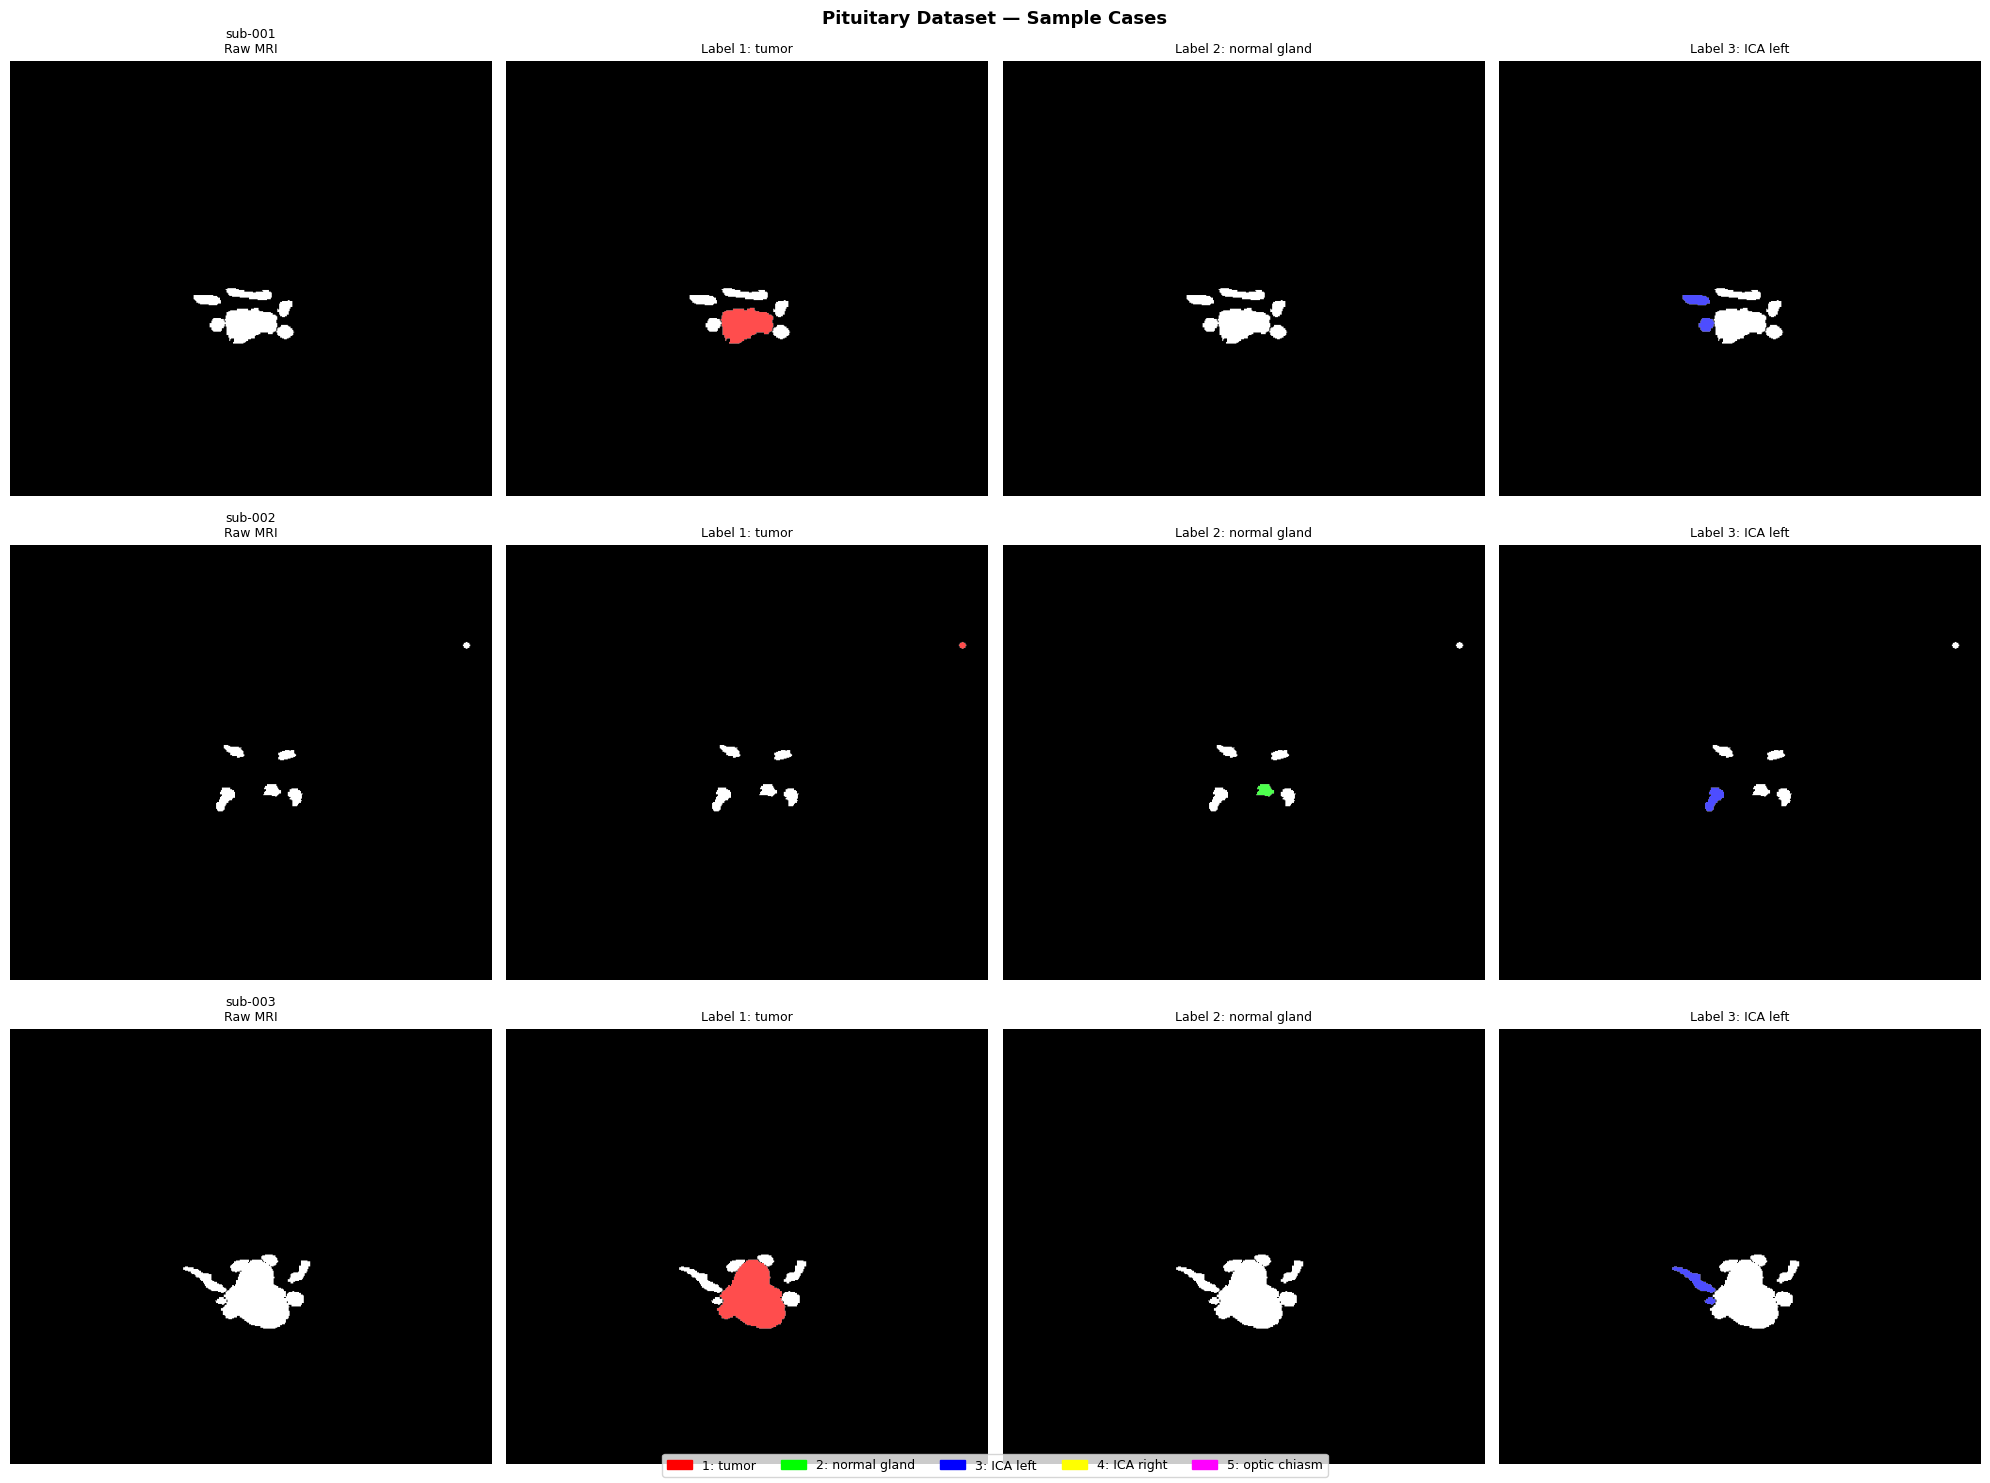


✅ Saved: pituitary_data_check.png


In [1]:
import os
import nibabel as nib
import numpy as np
from pathlib import Path
from collections import defaultdict
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ================= CONFIG =================
dataset_root = "/home/23bq1a4293/Personal/project/seg_data/pitutary/pituitary_tumor_dataset"
seg_dir      = Path(dataset_root) / "derivatives" / "segmentations"

LABELS = {0: "background", 1: "tumor", 2: "normal gland",
          3: "ICA left", 4: "ICA right", 5: "optic chiasm"}

# ================= COLLECT FILES =================
cases = []
for sub in sorted(seg_dir.iterdir()):
    if not sub.is_dir(): continue
    seg_path = sub / "anat" / f"{sub.name}_label-groundTruth.nii.gz"
    
    # Find the MRI image
    img_candidates = [
        Path(dataset_root) / sub.name / "anat" / f"{sub.name}_T1w.nii.gz",
        Path(dataset_root) / sub.name / "anat" / f"{sub.name}_ce-gadolinium_T1w.nii.gz",
    ]
    img_path = next((p for p in img_candidates if p.exists()), None)
    
    if seg_path.exists():
        cases.append({"pid": sub.name, "seg": seg_path, "img": img_path})

print(f"Total cases found: {len(cases)}")

# ================= ANALYZE EACH CASE =================
stats = []
label_presence = defaultdict(int)  # how many patients have each label

for c in cases:
    seg  = nib.load(c["seg"])
    arr  = seg.get_fdata().astype(np.uint8)
    sp   = seg.header.get_zooms()
    shp  = arr.shape

    present = {}
    for lbl, name in LABELS.items():
        if lbl == 0: continue
        count = (arr == lbl).sum()
        present[name] = int(count)
        if count > 0:
            label_presence[name] += 1

    stats.append({
        "pid":     c["pid"],
        "shape":   shp,
        "spacing": tuple(round(float(s), 4) for s in sp),
        "labels":  present,
        "has_img": c["img"] is not None,
    })

# ================= PRINT SUMMARY =================
print("\n" + "="*70)
print("DATASET SUMMARY")
print("="*70)

shapes  = [s["shape"]   for s in stats]
spacings= [s["spacing"] for s in stats]

unique_shapes   = set(shapes)
unique_spacings = set(spacings)

print(f"\n📐 Shapes ({len(unique_shapes)} unique):")
from collections import Counter
for shp, cnt in Counter(shapes).most_common():
    print(f"   {shp}  ×  {cnt} patients")

print(f"\n📏 Spacings ({len(unique_spacings)} unique):")
for sp, cnt in Counter(spacings).most_common():
    print(f"   {sp}  ×  {cnt} patients")

print(f"\n🏷️  Label presence across {len(cases)} patients:")
for lbl, name in LABELS.items():
    if lbl == 0: continue
    n = label_presence[name]
    print(f"   [{lbl}] {name:<20} present in {n:>2}/{len(cases)} patients  "
          f"({'⚠️  missing in some' if n < len(cases) else '✅ all'})")

print(f"\n🖼️  MRI image found: {sum(s['has_img'] for s in stats)}/{len(cases)}")

# ================= VOXEL COUNT STATS PER LABEL =================
print(f"\n📊 Voxel count stats per label (excluding zeros):")
for lbl, name in LABELS.items():
    if lbl == 0: continue
    counts = [s["labels"][name] for s in stats if s["labels"][name] > 0]
    if counts:
        print(f"   [{lbl}] {name:<20}  "
              f"min={min(counts):>7,}  max={max(counts):>7,}  "
              f"mean={int(np.mean(counts)):>7,}  median={int(np.median(counts)):>7,}")

# ================= PER-PATIENT TABLE =================
print(f"\n{'PID':<25} {'Shape':<20} {'Spacing':<30} Labels present")
print("-"*90)
for s in stats:
    present_lbls = [name for name, cnt in s["labels"].items() if cnt > 0]
    print(f"{s['pid']:<25} {str(s['shape']):<20} {str(s['spacing']):<30} {', '.join(present_lbls)}")

# ================= VISUALIZATION =================
# Show 3 random cases
sample_cases = [c for c in cases if c["img"] is not None][:3]
if not sample_cases:
    sample_cases = cases[:3]

fig, axes = plt.subplots(len(sample_cases), 4, figsize=(20, 5*len(sample_cases)))
if len(sample_cases) == 1:
    axes = [axes]

COLORS = {1:'red', 2:'lime', 3:'blue', 4:'yellow', 5:'magenta'}

for row, c in enumerate(sample_cases):
    seg_arr = nib.load(c["seg"]).get_fdata().astype(np.uint8)
    
    # Find thin axis
    thin_axis = int(np.argmin(seg_arr.shape))
    mid_slice  = seg_arr.shape[thin_axis] // 2
    
    # Get 2D slices along thin axis
    def get_slice(arr, axis, idx):
        if axis == 0: return arr[idx, :, :]
        if axis == 1: return arr[:, idx, :]
        return arr[:, :, idx]
    
    seg_2d = get_slice(seg_arr, thin_axis, mid_slice)
    
    # Load image if available
    if c["img"]:
        img_arr = nib.load(c["img"]).get_fdata(dtype=np.float32)
        img_2d  = get_slice(img_arr, thin_axis, mid_slice)
    else:
        img_2d = (seg_2d > 0).astype(np.float32)
    
    # Plot raw image
    axes[row][0].imshow(img_2d.T, cmap="gray", origin="lower", aspect="auto")
    axes[row][0].set_title(f"{c['pid']}\nRaw MRI", fontsize=9)
    axes[row][0].axis("off")
    
    # Plot each label separately
    for col, (lbl, name) in enumerate([(1,"tumor"),(2,"normal gland"),(3,"ICA left")], 1):
        axes[row][col].imshow(img_2d.T, cmap="gray", origin="lower", aspect="auto")
        mask = (seg_arr == lbl)
        if thin_axis == 0: mask_2d = mask[mid_slice, :, :]
        elif thin_axis == 1: mask_2d = mask[:, mid_slice, :]
        else: mask_2d = mask[:, :, mid_slice]
        
        overlay = np.zeros((*mask_2d.T.shape, 4))
        if mask_2d.any():
            c_rgb = plt.cm.colors.to_rgba(COLORS.get(lbl, 'white'))
            overlay[mask_2d.T] = (*c_rgb[:3], 0.7)
        axes[row][col].imshow(overlay, origin="lower", aspect="auto")
        axes[row][col].set_title(f"Label {lbl}: {name}", fontsize=9)
        axes[row][col].axis("off")

patches = [mpatches.Patch(color=c, label=f"{l}: {LABELS[l]}")
           for l, c in COLORS.items()]
fig.legend(handles=patches, loc="lower center", ncol=5, fontsize=9)
plt.suptitle("Pituitary Dataset — Sample Cases", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("pituitary_data_check.png", dpi=150, bbox_inches="tight")
plt.show()
print("\n✅ Saved: pituitary_data_check.png")

In [1]:
import os, json
import numpy as np
import nibabel as nib
import torch
from pathlib import Path
from scipy.ndimage import zoom
from collections import defaultdict
from monai.networks.nets import BasicUNet

# ── CONFIG (must match training) ──────────────────────────────────────
output_dir  = "/home/23bq1a4293/Personal/project/models/Segmentation/pituitary"
dataset_root = Path("/home/23bq1a4293/Personal/project/seg_data/pitutary/pituitary_tumor_dataset")
seg_root     = dataset_root / "derivatives" / "segmentations"
NUM_CLASSES  = 6
BATCH_SIZE   = 8
TARGET_SIZE  = (512, 512)
LABEL_NAMES  = ["tumor", "gland", "ICA-L", "ICA-R", "chiasm"]
device       = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ── LOAD CHECKPOINT ───────────────────────────────────────────────────
ckpt = torch.load(os.path.join(output_dir, "best_model.pth"),
                  map_location=device, weights_only=False)  # fix

model = BasicUNet(spatial_dims=2, in_channels=2, out_channels=NUM_CLASSES,
                  features=(32,32,64,128,256,32), act="PRELU",
                  norm="INSTANCE", dropout=0.1).to(device)
model.load_state_dict(ckpt["model"])
model.eval()
print(f"✅ Loaded best model — epoch {ckpt['epoch']}, Dice={ckpt['best_dice']:.4f}")

# ── LOAD VAL SPLIT ────────────────────────────────────────────────────
with open(os.path.join(output_dir, "train_val_split.json")) as f:
    split = json.load(f)
val_pids = split["val"]
print(f"Val patients: {val_pids}")

# ── RELOAD VAL SLICES ─────────────────────────────────────────────────
def normalize(arr):
    return ((arr - arr.mean()) / (arr.std() + 1e-8)).astype(np.float32)

val_slices = []
for pid in val_pids:
    ce_path  = dataset_root / pid / "anat" / f"{pid}_acq-CECor_T1w.nii.gz"
    cor_path = dataset_root / pid / "anat" / f"{pid}_acq-Cor_T1w.nii.gz"
    seg_path = seg_root / pid / "anat" / f"{pid}_label-groundTruth.nii.gz"

    ce_arr  = normalize(nib.load(ce_path).get_fdata(dtype=np.float32))
    cor_arr = normalize(nib.load(cor_path).get_fdata(dtype=np.float32))
    seg_arr = nib.load(seg_path).get_fdata().astype(np.uint8)

    H, D, W = seg_arr.shape
    if H != TARGET_SIZE[0] or W != TARGET_SIZE[1]:
        scale   = (TARGET_SIZE[0]/H, 1.0, TARGET_SIZE[1]/W)
        from scipy.ndimage import zoom
        ce_arr  = zoom(ce_arr,  scale, order=1)
        cor_arr = zoom(cor_arr, scale, order=1)
        seg_arr = zoom(seg_arr, scale, order=0)

    for y in range(seg_arr.shape[1]):
        val_slices.append({
            "image": np.stack([ce_arr[:,y,:], cor_arr[:,y,:]], axis=0),
            "label": seg_arr[:,y,:].astype(np.int64),
            "pid":   pid,
        })

# ── PER-PATIENT EVALUATION ────────────────────────────────────────────
patient_slices = defaultdict(list)
for i, s in enumerate(val_slices):
    patient_slices[s["pid"]].append(i)

print(f"\n{'PID':<12} {'Tumor':>7} {'Gland':>7} {'ICA-L':>7} {'ICA-R':>7} {'Chiasm':>7} {'Mean':>7}")
print("-"*58)

all_dices = []
with torch.no_grad():
    for pid, indices in sorted(patient_slices.items()):
        imgs = torch.stack(
            [torch.from_numpy(val_slices[i]["image"]).float() for i in indices]
        ).to(device)
        lbls = torch.stack(
            [torch.from_numpy(val_slices[i]["label"]).long() for i in indices]
        ).to(device)

        preds = torch.cat([
            torch.argmax(model(imgs[s:s+BATCH_SIZE]), dim=1)
            for s in range(0, len(imgs), BATCH_SIZE)
        ], dim=0)

        row = []
        for cls in range(1, NUM_CLASSES):
            p = (preds == cls).float()
            g = (lbls  == cls).float()
            denom = p.sum() + g.sum()
            row.append((2*(p*g).sum()/denom).item() if denom > 0 else float("nan"))

        all_dices.append(row)
        vals = "  ".join(f"{v:7.3f}" if not np.isnan(v) else "    nan" for v in row)
        print(f"{pid:<12} {vals}  {np.nanmean(row):7.3f}")

arr = np.array(all_dices)
print("-"*58)
print("Mean        " + "  ".join(f"{m:7.3f}" for m in np.nanmean(arr, axis=0)) +
      f"  {np.nanmean(arr):7.3f}")
print("Std         " + "  ".join(f"{s:7.3f}" for s in np.nanstd(arr,  axis=0)))

/home/23bq1a4293/.local/lib/python3.11/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.0.7) or chardet (6.0.0.post1)/charset_normalizer (2.0.4) doesn't match a supported version!
  warnings.warn(
<frozen importlib._bootstrap_external>:1241: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.


BasicUNet features: (32, 32, 64, 128, 256, 32).
✅ Loaded best model — epoch 63, Dice=0.6442
Val patients: ['sub-026', 'sub-024', 'sub-020', 'sub-012', 'sub-005', 'sub-046', 'sub-027', 'sub-010', 'sub-030', 'sub-017']

PID            Tumor   Gland   ICA-L   ICA-R  Chiasm    Mean
----------------------------------------------------------
sub-005        0.866    0.000    0.736    0.798    0.435    0.567
sub-010        0.869    0.000    0.708    0.623    0.198    0.480
sub-012        0.712    0.451    0.804    0.766    0.658    0.678
sub-017        0.923    0.000    0.774    0.824    0.588    0.622
sub-020        0.715    0.000    0.799    0.793    0.651    0.591
sub-024        0.750    0.418    0.785    0.865    0.518    0.667
sub-026        0.816    0.480    0.814    0.770    0.582    0.693
sub-027        0.765    0.000    0.659    0.755    0.638    0.563
sub-030        0.914    0.000    0.806    0.808    0.530    0.612
sub-046        0.810    0.446    0.587    0.702    0.526    0.614
--

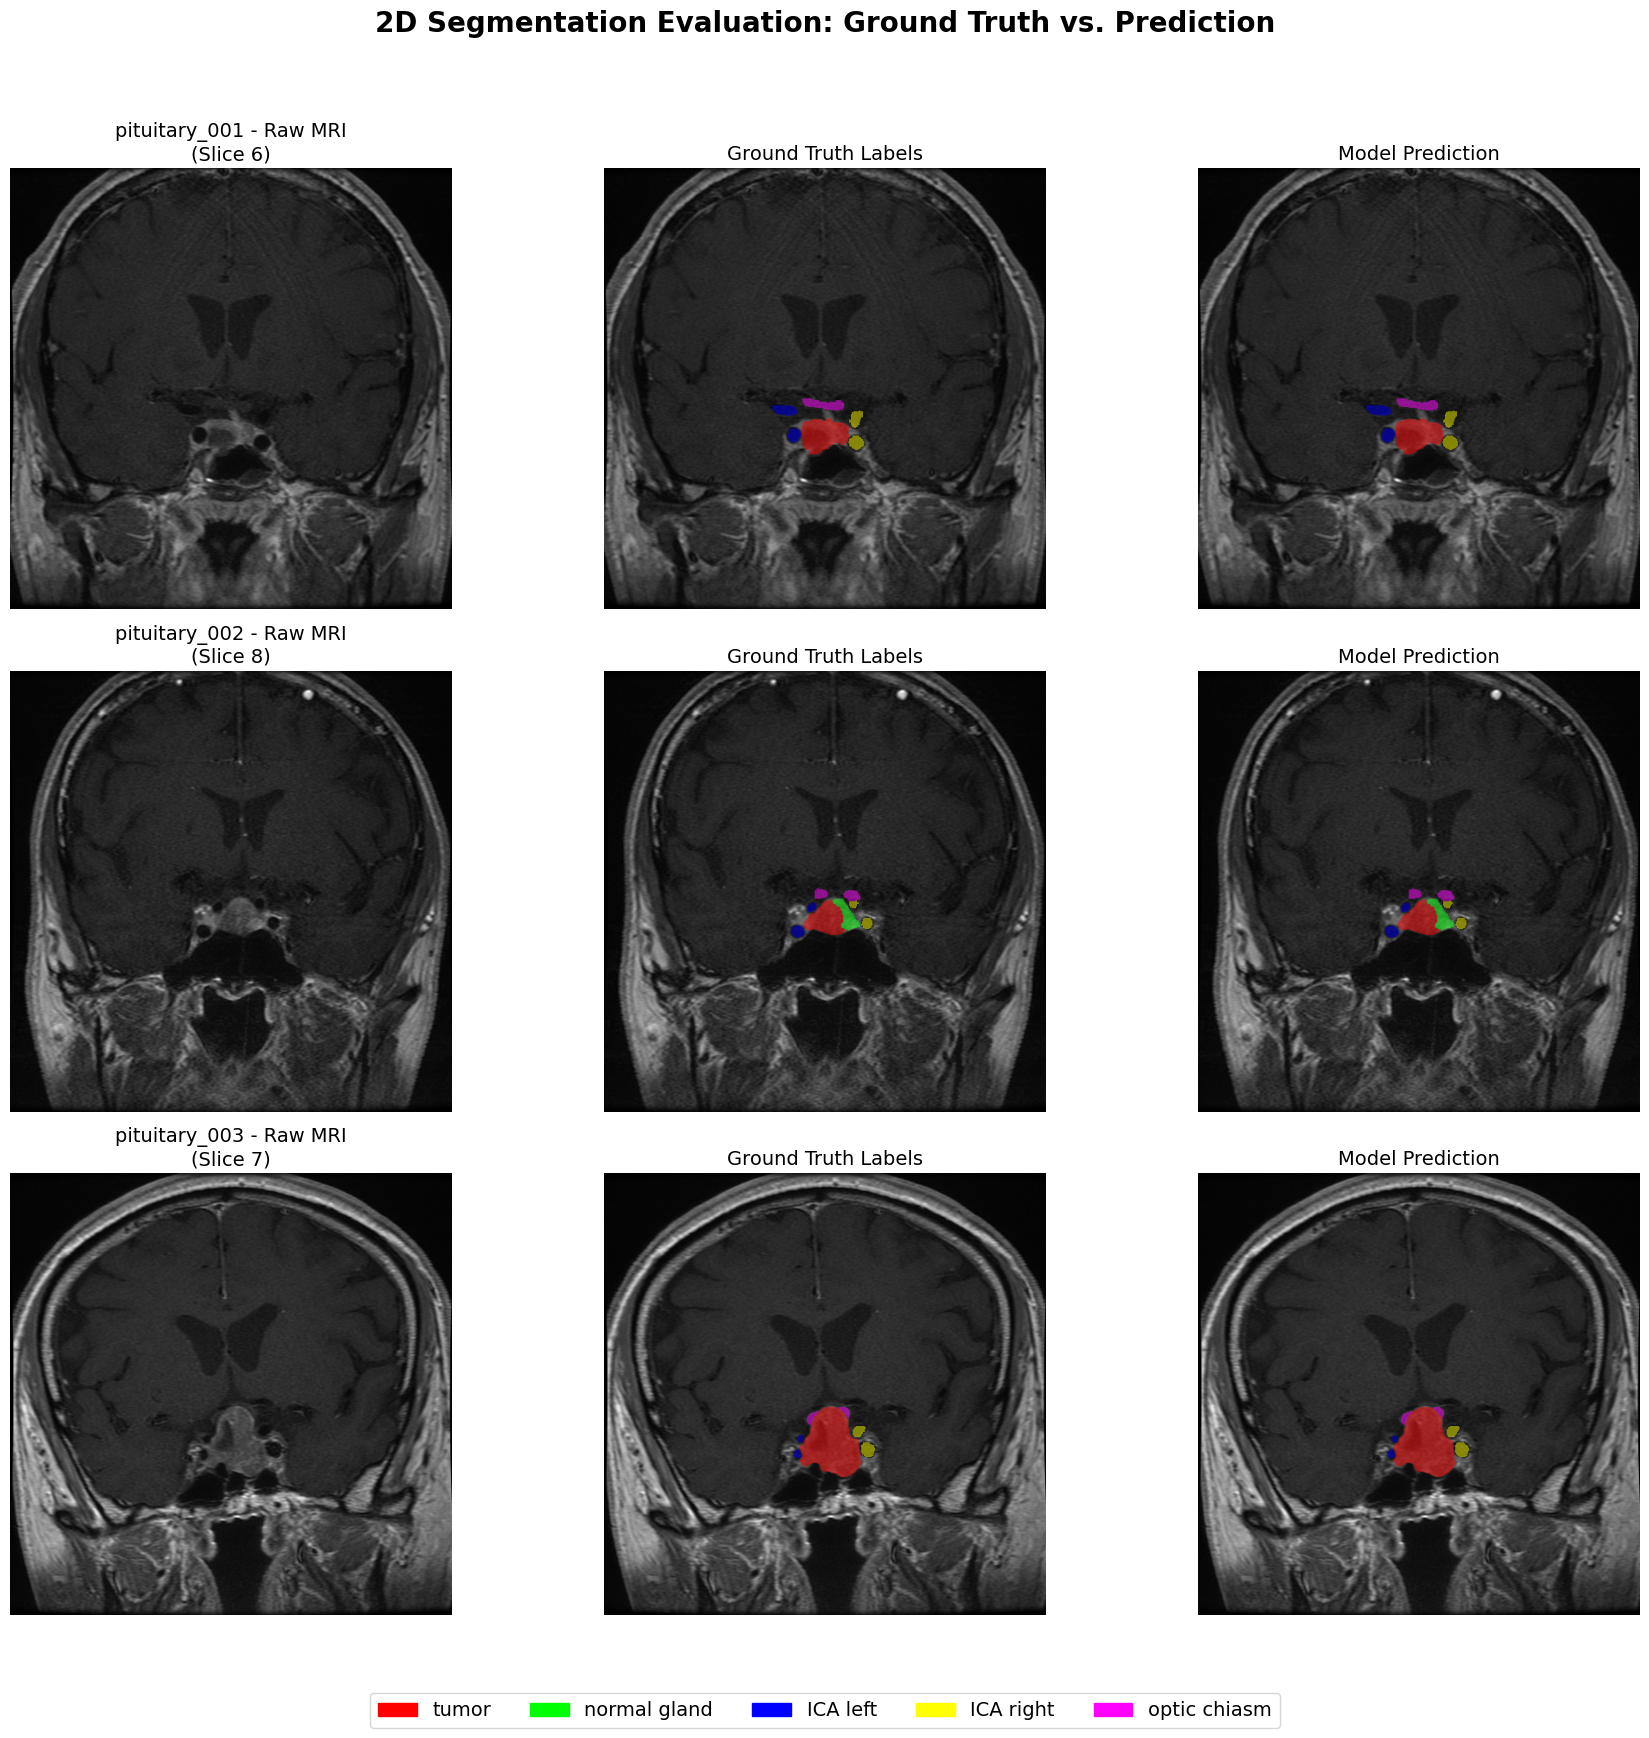

In [4]:
import os
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

# ==========================================
# 1. CONFIGURATION
# ==========================================
patients_to_plot = ["pituitary_001", "pituitary_002", "pituitary_003"]

raw_dir = Path('/home/23bq1a4293/Personal/project/nnunet/nnUNet_raw/Dataset001_Pituitary')
# Make sure this points to the prediction folder you want to evaluate!
pred_dir = Path('/home/23bq1a4293/Personal/project/nnunet/predictions_fold0_val') 

COLORS = {
    1: [255, 0, 0],      # tumor - red
    2: [0, 255, 0],      # normal gland - green
    3: [0, 0, 255],      # ICA left - blue
    4: [255, 255, 0],    # ICA right - yellow
    5: [255, 0, 255],    # optic chiasm - magenta
}
LABELS = {1:'tumor', 2:'normal gland', 3:'ICA left', 4:'ICA right', 5:'optic chiasm'}

def overlay_all_classes(image, seg, alpha=0.5):
    """Overlays ALL present class masks onto the grayscale image simultaneously."""
    img_norm = (image - image.min()) / (image.max() - image.min() + 1e-8)
    rgb = np.stack([img_norm]*3, axis=-1)
    
    for class_idx, color in COLORS.items():
        mask = seg == class_idx
        if mask.any():
            for c, col_val in enumerate(color):
                rgb[:, :, c] = np.where(mask, 
                    rgb[:, :, c] * (1-alpha) + (col_val/255) * alpha,
                    rgb[:, :, c])
    return rgb

# ==========================================
# 2. PLOTTING LOGIC
# ==========================================
# 3 columns: Raw MRI | Ground Truth | Prediction
fig, axes = plt.subplots(len(patients_to_plot), 3, figsize=(18, 6 * len(patients_to_plot)))
fig.suptitle('2D Segmentation Evaluation: Ground Truth vs. Prediction', fontsize=20, fontweight='bold', y=0.98)

if len(patients_to_plot) == 1:
    axes = np.expand_dims(axes, axis=0)

for row_idx, patient_id in enumerate(patients_to_plot):
    img_path = raw_dir / "imagesTr" / f"{patient_id}_0000.nii.gz"
    gt_path = raw_dir / "labelsTr" / f"{patient_id}.nii.gz"
    
    # Check if prediction is .nii or .nii.gz
    pred_ext = ".nii" if Path(f"{pred_dir}/{patient_id}.nii").exists() else ".nii.gz"
    pred_path = pred_dir / f"{patient_id}{pred_ext}"
    
    img = nib.load(img_path).get_fdata()
    gt = nib.load(gt_path).get_fdata()
    
    # Load prediction (if it exists) or just create an empty array if missing
    if pred_path.exists():
        pred = nib.load(pred_path).get_fdata()
    else:
        print(f"Warning: No prediction found for {patient_id}. Showing blank mask.")
        pred = np.zeros_like(img)
    
    # Target Axis 1 (Coronal depth) based on the Ground Truth tumor location
    tumor_mask = (gt == 1)
    if tumor_mask.any():
        best_slice = np.argmax(tumor_mask.sum(axis=(0, 2))) 
    else:
        best_slice = img.shape[1] // 2
    
    img_sl = img[:, best_slice, :]
    gt_sl = gt[:, best_slice, :]
    pred_sl = pred[:, best_slice, :]
    
    # Column 0: Raw MRI
    axes[row_idx, 0].imshow(img_sl.T, cmap='gray', origin='lower')
    axes[row_idx, 0].set_title(f'{patient_id} - Raw MRI\n(Slice {best_slice})', fontsize=14)
    axes[row_idx, 0].axis('off')
    
    # Column 1: Ground Truth Overlay
    gt_overlay = overlay_all_classes(img_sl, gt_sl)
    axes[row_idx, 1].imshow(gt_overlay.transpose(1,0,2), origin='lower')
    axes[row_idx, 1].set_title(f'Ground Truth Labels', fontsize=14)
    axes[row_idx, 1].axis('off')

    # Column 2: Prediction Overlay
    pred_overlay = overlay_all_classes(img_sl, pred_sl)
    axes[row_idx, 2].imshow(pred_overlay.transpose(1,0,2), origin='lower')
    axes[row_idx, 2].set_title(f'Model Prediction', fontsize=14)
    axes[row_idx, 2].axis('off')

# ==========================================
# 3. LEGEND & RENDER
# ==========================================
patches = [mpatches.Patch(color=[c/255 for c in col], label=LABELS[cls]) for cls, col in COLORS.items()]
fig.legend(handles=patches, loc='lower center', ncol=5, fontsize=14, bbox_to_anchor=(0.5, 0.02))

plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.show()

In [2]:
import h5py
from pathlib import Path

mat_dir = Path("/home/23bq1a4293/Personal/project/nnunet/external_test/imagesTr")
for mat_file in sorted(mat_dir.glob("*.mat"))[:4]:
    print(f"\n{'='*40}")
    print(f"File: {mat_file.name}")
    with h5py.File(str(mat_file), 'r') as f:
        def print_structure(name, obj):
            if isinstance(obj, h5py.Dataset):
                print(f"  Key: '{name}' | Shape: {obj.shape} | Dtype: {obj.dtype}")
        f.visititems(print_structure)


File: 2299.mat
  Key: 'cjdata/PID' | Shape: (9, 1) | Dtype: uint16
  Key: 'cjdata/image' | Shape: (512, 512) | Dtype: int16
  Key: 'cjdata/label' | Shape: (1, 1) | Dtype: float64
  Key: 'cjdata/tumorBorder' | Shape: (1, 42) | Dtype: float64
  Key: 'cjdata/tumorMask' | Shape: (512, 512) | Dtype: uint8

File: 2300.mat
  Key: 'cjdata/PID' | Shape: (9, 1) | Dtype: uint16
  Key: 'cjdata/image' | Shape: (512, 512) | Dtype: int16
  Key: 'cjdata/label' | Shape: (1, 1) | Dtype: float64
  Key: 'cjdata/tumorBorder' | Shape: (1, 22) | Dtype: float64
  Key: 'cjdata/tumorMask' | Shape: (512, 512) | Dtype: uint8

File: 2301.mat
  Key: 'cjdata/PID' | Shape: (9, 1) | Dtype: uint16
  Key: 'cjdata/image' | Shape: (512, 512) | Dtype: int16
  Key: 'cjdata/label' | Shape: (1, 1) | Dtype: float64
  Key: 'cjdata/tumorBorder' | Shape: (1, 34) | Dtype: float64
  Key: 'cjdata/tumorMask' | Shape: (512, 512) | Dtype: uint8

File: 2302.mat
  Key: 'cjdata/PID' | Shape: (9, 1) | Dtype: uint16
  Key: 'cjdata/image' |

In [4]:
import os
import json
import numpy as np
import nibabel as nib
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from pathlib import Path
from scipy.ndimage import zoom

# ── PATHS ──────────────────────────────────────────────────────────────
DATASET_ROOT = Path("/home/23bq1a4293/Personal/project/seg_data/pitutary/pituitary_tumor_dataset")
SEG_ROOT     = DATASET_ROOT / "derivatives" / "segmentations"
NNUNET_RAW   = Path("/home/23bq1a4293/Personal/project/nnunet/nnUNet_raw/Dataset001_Pituitary")
RESULTS_DIR  = Path("/home/23bq1a4293/Personal/project/nnunet/nnUNet_results/Dataset001_Pituitary/nnUNetTrainer__nnUNetPlans__2d")

# 4 truly unseen patients
TEST_PIDS = ["pituitary_001", "pituitary_002", "pituitary_005", "pituitary_007"]

LABEL_NAMES  = {0:"background", 1:"tumor", 2:"normal gland", 
                3:"ICA left", 4:"ICA right", 5:"optic chiasm"}
LABEL_COLORS = {0:[0,0,0,0], 1:[1,0,0,0.7], 2:[0,1,0,0.7], 
                3:[0,0,1,0.7], 4:[1,1,0,0.7], 5:[1,0,1,0.7]}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print(f"Test patients: {TEST_PIDS}")

/home/23bq1a4293/.local/lib/python3.11/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.0.7) or chardet (6.0.0.post1)/charset_normalizer (2.0.4) doesn't match a supported version!
  warnings.warn(


Device: cuda
Test patients: ['pituitary_001', 'pituitary_002', 'pituitary_005', 'pituitary_007']


In [5]:
def normalize(arr):
    return ((arr - arr.mean()) / (arr.std() + 1e-8)).astype(np.float32)

def load_patient(pid):
    """Load CE T1w + Cor T1w + GT segmentation for a patient."""
    sub = pid.replace("pituitary_", "sub-").replace("_0", "-0")
    # Map pituitary_001 → sub-001
    num = pid.split("_")[1]
    sub = f"sub-{num}"

    ce_path  = DATASET_ROOT / sub / "anat" / f"{sub}_acq-CECor_T1w.nii.gz"
    cor_path = DATASET_ROOT / sub / "anat" / f"{sub}_acq-Cor_T1w.nii.gz"
    seg_path = SEG_ROOT / sub / "anat" / f"{sub}_label-groundTruth.nii.gz"

    ce_arr  = nib.load(ce_path).get_fdata(dtype=np.float32)
    cor_arr = nib.load(cor_path).get_fdata(dtype=np.float32)
    seg_arr = nib.load(seg_path).get_fdata().astype(np.uint8)

    # Downsample 1024→512 if needed
    H, D, W = seg_arr.shape
    if H != 512 or W != 512:
        scale   = (512/H, 1.0, 512/W)
        ce_arr  = zoom(ce_arr,  scale, order=1)
        cor_arr = zoom(cor_arr, scale, order=1)
        seg_arr = zoom(seg_arr, scale, order=0)

    return {
        "pid":    pid,
        "sub":    sub,
        "ce":     normalize(ce_arr),
        "cor":    normalize(cor_arr),
        "seg":    seg_arr,
        "shape":  seg_arr.shape,
    }

patients = {}
for pid in TEST_PIDS:
    patients[pid] = load_patient(pid)
    p = patients[pid]
    print(f"✅ {pid} ({p['sub']}) | Shape: {p['shape']} | "
          f"Labels: {np.unique(p['seg'])}")

✅ pituitary_001 (sub-001) | Shape: (512, 13, 512) | Labels: [0 1 3 4 5]
✅ pituitary_002 (sub-002) | Shape: (512, 11, 512) | Labels: [0 1 2 3 4 5]
✅ pituitary_005 (sub-005) | Shape: (512, 11, 512) | Labels: [0 1 3 4 5]
✅ pituitary_007 (sub-007) | Shape: (512, 11, 512) | Labels: [0 1 3 4 5]


In [9]:
import os
os.environ['MKL_THREADING_LAYER'] = 'GNU'

import torch
import numpy as np
import torch.nn.functional as F
from pathlib import Path
from dynamic_network_architectures.architectures.unet import PlainConvUNet

# ── Load model architecture (matches nnU-Net 2D plan) ──────────────────
def load_fold_model(fold, device):
    model = PlainConvUNet(
        input_channels=1,
        n_stages=8,
        features_per_stage=(32, 64, 128, 256, 512, 512, 512, 512),
        conv_op=torch.nn.Conv2d,
        kernel_sizes=[[3,3]]*8,
        strides=[[1,1],[2,2],[2,2],[2,2],[2,2],[2,2],[2,2],[2,2]],
        n_conv_per_stage=[2]*8,
        num_classes=6,
        n_conv_per_stage_decoder=[2]*7,
        conv_bias=True,
        norm_op=torch.nn.InstanceNorm2d,
        norm_op_kwargs={'eps':1e-5,'affine':True},
        dropout_op=None,
        dropout_op_kwargs=None,
        nonlin=torch.nn.LeakyReLU,
        nonlin_kwargs={'inplace':True},
        deep_supervision=False,
    ).to(device)

    ckpt_path = RESULTS_DIR / f"fold_{fold}" / "checkpoint_best.pth"
    ckpt = torch.load(str(ckpt_path), map_location=device, weights_only=False)
    # Extract network weights
    state = {k.replace("network.", ""): v
             for k, v in ckpt['network_weights'].items()}
    model.load_state_dict(state)
    model.eval()
    print(f"✅ Fold {fold} model loaded from {ckpt_path}")
    return model

model_f0 = load_fold_model(0, device)
model_f1 = load_fold_model(1, device)

# ── Inference per slice, ensemble fold0+fold1 ──────────────────────────
def predict_volume(patients_dict, model_f0, model_f1, device):
    predictions = {}
    for pid, p in patients_dict.items():
        print(f"Inferring {pid}...")
        ce  = p["ce"]   # (512, D, 512)
        cor = p["cor"]

        D = ce.shape[1]
        pred_volume = np.zeros(ce.shape, dtype=np.uint8)

        with torch.no_grad():
            for y in range(D):
                # Use only CE channel (model trained on 1 channel nnUNet input)
                ce_sl  = torch.from_numpy(ce[:, y, :]).float().unsqueeze(0).unsqueeze(0).to(device)

                out_f0 = F.softmax(model_f0(ce_sl)[0] if isinstance(model_f0(ce_sl), (list,tuple))
                                   else model_f0(ce_sl), dim=1)
                out_f1 = F.softmax(model_f1(ce_sl)[0] if isinstance(model_f1(ce_sl), (list,tuple))
                                   else model_f1(ce_sl), dim=1)

                ensemble = (out_f0 + out_f1) / 2.0
                pred_sl  = torch.argmax(ensemble, dim=1).squeeze(0).cpu().numpy().astype(np.uint8)
                pred_volume[:, y, :] = pred_sl

        predictions[pid] = pred_volume
        print(f"  ✅ {pid} | Shape: {pred_volume.shape} | Labels: {np.unique(pred_volume)}")
    return predictions

predictions = predict_volume(patients, model_f0, model_f1, device)

✅ Fold 0 model loaded from /home/23bq1a4293/Personal/project/nnunet/nnUNet_results/Dataset001_Pituitary/nnUNetTrainer__nnUNetPlans__2d/fold_0/checkpoint_best.pth
✅ Fold 1 model loaded from /home/23bq1a4293/Personal/project/nnunet/nnUNet_results/Dataset001_Pituitary/nnUNetTrainer__nnUNetPlans__2d/fold_1/checkpoint_best.pth
Inferring pituitary_001...
  ✅ pituitary_001 | Shape: (512, 13, 512) | Labels: [0 1 3 4 5]
Inferring pituitary_002...
  ✅ pituitary_002 | Shape: (512, 11, 512) | Labels: [0 1 2 3 4 5]
Inferring pituitary_005...
  ✅ pituitary_005 | Shape: (512, 11, 512) | Labels: [0 1 3 4 5]
Inferring pituitary_007...
  ✅ pituitary_007 | Shape: (512, 11, 512) | Labels: [0 1 3 4 5]


In [10]:
def dice_score(pred, gt, cls):
    p = (pred == cls).astype(float)
    g = (gt   == cls).astype(float)
    denom = p.sum() + g.sum()
    return 2*(p*g).sum()/denom if denom > 0 else float('nan')

LABEL_NAMES_SHORT = ["tumor", "gland", "ICA-L", "ICA-R", "chiasm"]

print(f"\n{'PID':<20} {'Tumor':>7} {'Gland':>7} {'ICA-L':>7} {'ICA-R':>7} {'Chiasm':>7} {'Mean':>7}")
print("-"*62)

all_dices = []
for pid in TEST_PIDS:
    pred = predictions[pid]
    gt   = patients[pid]["seg"]
    row  = [dice_score(pred, gt, cls) for cls in range(1, 6)]
    all_dices.append(row)
    vals = "  ".join(f"{v:7.3f}" if not np.isnan(v) else "    nan" for v in row)
    print(f"{pid:<20} {vals}  {np.nanmean(row):7.3f}")

arr = np.array(all_dices)
print("-"*62)
print("Mean                " +
      "  ".join(f"{m:7.3f}" for m in np.nanmean(arr, axis=0)) +
      f"  {np.nanmean(arr):7.3f}")
print("Std                 " +
      "  ".join(f"{s:7.3f}" for s in np.nanstd(arr, axis=0)))


PID                    Tumor   Gland   ICA-L   ICA-R  Chiasm    Mean
--------------------------------------------------------------
pituitary_001          0.928      nan    0.913    0.934    0.854    0.907
pituitary_002          0.924    0.918    0.903    0.909    0.814    0.894
pituitary_005          0.965      nan    0.934    0.908    0.864    0.918
pituitary_007          0.957      nan    0.929    0.912    0.825    0.906
--------------------------------------------------------------
Mean                  0.943    0.918    0.920    0.916    0.839    0.905
Std                   0.018    0.000    0.013    0.011    0.020


In [11]:
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec

COLORS = {
    1: [1.0, 0.0, 0.0],   # tumor — red
    2: [0.0, 1.0, 0.0],   # gland — green
    3: [0.0, 0.4, 1.0],   # ICA-L — blue
    4: [1.0, 1.0, 0.0],   # ICA-R — yellow
    5: [1.0, 0.0, 1.0],   # chiasm — magenta
}
NAMES = {1:"Tumor", 2:"Gland", 3:"ICA-L", 4:"ICA-R", 5:"Chiasm"}

def overlay(img, seg, alpha=0.55):
    mn, mx = img.min(), img.max()
    img_n  = (img - mn) / (mx - mn + 1e-8)
    rgb    = np.stack([img_n]*3, axis=-1).copy()
    for cls, col in COLORS.items():
        mask = seg == cls
        if not mask.any(): continue
        for c in range(3):
            rgb[:,:,c] = np.where(mask,
                rgb[:,:,c]*(1-alpha) + col[c]*alpha,
                rgb[:,:,c])
    return np.clip(rgb, 0, 1)

legend_patches = [
    mpatches.Patch(color=COLORS[i], label=NAMES[i])
    for i in range(1, 6)
]

OUT_DIR = Path("/home/23bq1a4293/Personal/project/nnunet/external_test/results")
OUT_DIR.mkdir(exist_ok=True)

for pid in TEST_PIDS:
    p        = patients[pid]
    pred     = predictions[pid]
    gt       = p["seg"]
    ce       = p["ce"]
    n_slices = ce.shape[1]

    # Compute dice
    row  = [dice_score(pred, gt, cls) for cls in range(1, 6)]
    mean = np.nanmean(row)

    fig, axes = plt.subplots(n_slices, 4,
                             figsize=(20, 5*n_slices),
                             squeeze=False)

    for y in range(n_slices):
        ce_sl   = ce[:, y, :]
        gt_sl   = gt[:, y, :]
        pred_sl = pred[:, y, :]

        # Raw MRI
        axes[y][0].imshow(ce_sl.T, cmap="gray",
                          origin="lower", aspect="auto")
        axes[y][0].set_title(f"CE T1w | Slice {y}", fontsize=10)
        axes[y][0].axis("off")

        # GT overlay
        axes[y][1].imshow(overlay(ce_sl, gt_sl).transpose(1,0,2),
                          origin="lower", aspect="auto")
        axes[y][1].set_title("Ground Truth", fontsize=10)
        axes[y][1].axis("off")

        # Pred overlay
        axes[y][2].imshow(overlay(ce_sl, pred_sl).transpose(1,0,2),
                          origin="lower", aspect="auto")
        axes[y][2].set_title("Prediction (Fold0+1 Ensemble)", fontsize=10)
        axes[y][2].axis("off")

        # Error map
        diff = (gt_sl != pred_sl).astype(float)
        axes[y][3].imshow(ce_sl.T, cmap="gray",
                          origin="lower", aspect="auto")
        axes[y][3].imshow(diff.T, cmap="Reds", alpha=0.7,
                          origin="lower", aspect="auto")
        axes[y][3].set_title("Error Map (red=wrong)", fontsize=10)
        axes[y][3].axis("off")

    fig.legend(handles=legend_patches, loc="lower center",
               ncol=5, fontsize=10, bbox_to_anchor=(0.5, -0.01),
               frameon=True)

    dice_str = " | ".join(
        f"{n}:{v:.3f}" if not np.isnan(v) else f"{n}:nan"
        for n, v in zip(LABEL_NAMES_SHORT, row)
    )
    plt.suptitle(
        f"{pid} — Mean Dice: {mean:.3f}\n{dice_str}",
        fontsize=12, fontweight="bold", y=1.01
    )
    plt.tight_layout()

    save_path = OUT_DIR / f"{pid}_inference.png"
    plt.savefig(str(save_path), dpi=120, bbox_inches="tight")
    plt.show()
    print(f"✅ Saved: {save_path}")

print(f"\n✅ All visualizations saved to: {OUT_DIR}")

✅ Saved: /home/23bq1a4293/Personal/project/nnunet/external_test/results/pituitary_001_inference.png
✅ Saved: /home/23bq1a4293/Personal/project/nnunet/external_test/results/pituitary_002_inference.png
✅ Saved: /home/23bq1a4293/Personal/project/nnunet/external_test/results/pituitary_005_inference.png
✅ Saved: /home/23bq1a4293/Personal/project/nnunet/external_test/results/pituitary_007_inference.png

✅ All visualizations saved to: /home/23bq1a4293/Personal/project/nnunet/external_test/results


In [1]:
"""
CORRECT EVALUATION — Each fold model evaluated on its own val patients only
Run this as a Jupyter notebook cell by cell
"""

# ============================================================
# CELL 1 — Setup
# ============================================================
import os
os.environ['MKL_THREADING_LAYER'] = 'GNU'

import json
import numpy as np
import nibabel as nib
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from scipy.ndimage import zoom
from dynamic_network_architectures.architectures.unet import PlainConvUNet

DATASET_ROOT = Path("/home/23bq1a4293/Personal/project/seg_data/pitutary/pituitary_tumor_dataset")
SEG_ROOT     = DATASET_ROOT / "derivatives" / "segmentations"
RESULTS_DIR  = Path("/home/23bq1a4293/Personal/project/nnunet/nnUNet_results/Dataset001_Pituitary/nnUNetTrainer__nnUNetPlans__2d")
OUT_DIR      = Path("/home/23bq1a4293/Personal/project/nnunet/external_test/correct_eval")
OUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

LABEL_NAMES  = ["tumor", "gland", "ICA-L", "ICA-R", "chiasm"]
COLORS = {1:[1,0,0], 2:[0,1,0], 3:[0,0.4,1], 4:[1,1,0], 5:[1,0,1]}
NAMES  = {1:"Tumor", 2:"Gland", 3:"ICA-L", 4:"ICA-R", 5:"Chiasm"}

# Fold val patients
FOLD_VAL = {
    0: ['pituitary_009','pituitary_013','pituitary_022','pituitary_023',
        'pituitary_031','pituitary_033','pituitary_034','pituitary_039',
        'pituitary_043','pituitary_046'],
    1: ['pituitary_003','pituitary_004','pituitary_006','pituitary_020',
        'pituitary_021','pituitary_026','pituitary_029','pituitary_032',
        'pituitary_040','pituitary_044'],
}
print(f"Fold 0 val: {FOLD_VAL[0]}")
print(f"Fold 1 val: {FOLD_VAL[1]}")


# ============================================================
# CELL 2 — Load model
# ============================================================
def load_model(fold):
    model = PlainConvUNet(
        input_channels=1,
        n_stages=8,
        features_per_stage=(32,64,128,256,512,512,512,512),
        conv_op=torch.nn.Conv2d,
        kernel_sizes=[[3,3]]*8,
        strides=[[1,1],[2,2],[2,2],[2,2],[2,2],[2,2],[2,2],[2,2]],
        n_conv_per_stage=[2]*8,
        num_classes=6,
        n_conv_per_stage_decoder=[2]*7,
        conv_bias=True,
        norm_op=torch.nn.InstanceNorm2d,
        norm_op_kwargs={'eps':1e-5,'affine':True},
        dropout_op=None, dropout_op_kwargs=None,
        nonlin=torch.nn.LeakyReLU,
        nonlin_kwargs={'inplace':True},
        deep_supervision=False,
    ).to(device)

    ckpt_path = RESULTS_DIR / f"fold_{fold}" / "checkpoint_best.pth"
    ckpt  = torch.load(str(ckpt_path), map_location=device, weights_only=False)
    state = {k.replace("network.", ""): v for k, v in ckpt['network_weights'].items()}
    model.load_state_dict(state)
    model.eval()
    print(f"✅ Fold {fold} model loaded")
    return model

model_f0 = load_model(0)
model_f1 = load_model(1)


# ============================================================
# CELL 3 — Load patient data
# ============================================================
def normalize(arr):
    return ((arr - arr.mean()) / (arr.std() + 1e-8)).astype(np.float32)

def load_patient(pid):
    num = pid.split("_")[1]
    sub = f"sub-{num}"
    ce_path  = DATASET_ROOT / sub / "anat" / f"{sub}_acq-CECor_T1w.nii.gz"
    seg_path = SEG_ROOT / sub / "anat" / f"{sub}_label-groundTruth.nii.gz"
    ce_arr  = nib.load(ce_path).get_fdata(dtype=np.float32)
    seg_arr = nib.load(seg_path).get_fdata().astype(np.uint8)
    H, D, W = seg_arr.shape
    if H != 512 or W != 512:
        scale   = (512/H, 1.0, 512/W)
        ce_arr  = zoom(ce_arr,  scale, order=1)
        seg_arr = zoom(seg_arr, scale, order=0)
    return {"pid": pid, "ce": normalize(ce_arr), "seg": seg_arr}

def predict(model, patient):
    ce   = patient["ce"]  # (512, D, 512)
    D    = ce.shape[1]
    pred = np.zeros(ce.shape, dtype=np.uint8)
    with torch.no_grad():
        for y in range(D):
            sl     = torch.from_numpy(ce[:,y,:]).float().unsqueeze(0).unsqueeze(0).to(device)
            out    = model(sl)
            out    = out[0] if isinstance(out, (list, tuple)) else out
            pred[:,y,:] = torch.argmax(F.softmax(out, dim=1), dim=1).squeeze(0).cpu().numpy()
    return pred

def dice(pred, gt, cls):
    p = (pred==cls).astype(float); g = (gt==cls).astype(float)
    d = p.sum()+g.sum()
    return 2*(p*g).sum()/d if d > 0 else float('nan')


# ============================================================
# CELL 4 — Correct evaluation
# ============================================================
all_results = {}

for fold, model in [(0, model_f0), (1, model_f1)]:
    print(f"\n{'='*60}")
    print(f"FOLD {fold} — evaluating on {len(FOLD_VAL[fold])} unseen patients")
    print(f"{'='*60}")

    for pid in FOLD_VAL[fold]:
        try:
            p    = load_patient(pid)
            pred = predict(model, p)
            row  = [dice(pred, p["seg"], cls) for cls in range(1, 6)]
            all_results[pid] = {"fold": fold, "dice": row, "pred": pred, "patient": p}
            vals = "  ".join(f"{v:7.3f}" if not np.isnan(v) else "    nan" for v in row)
            print(f"  {pid}: {vals}  mean={np.nanmean(row):.3f}")
        except Exception as e:
            print(f"  ⚠️ {pid}: {e}")

# Summary
print(f"\n{'='*60}")
print("FINAL SUMMARY — Truly unseen patients")
print(f"{'='*60}")
print(f"\n{'PID':<20} {'Tumor':>7} {'Gland':>7} {'ICA-L':>7} {'ICA-R':>7} {'Chiasm':>7} {'Mean':>7}")
print("-"*62)

arr = []
for pid in sorted(all_results.keys()):
    row  = all_results[pid]["dice"]
    vals = "  ".join(f"{v:7.3f}" if not np.isnan(v) else "    nan" for v in row)
    print(f"{pid:<20} {vals}  {np.nanmean(row):7.3f}")
    arr.append(row)

arr = np.array(arr)
print("-"*62)
print("Mean                " + "  ".join(f"{m:7.3f}" for m in np.nanmean(arr, axis=0)) +
      f"  {np.nanmean(arr):7.3f}")
print("Std                 " + "  ".join(f"{s:7.3f}" for s in np.nanstd(arr, axis=0)))


# ============================================================
# CELL 5 — Visualization (best slice per patient)
# ============================================================
def overlay(img, seg, alpha=0.55):
    mn, mx = img.min(), img.max()
    rgb = np.stack([(img-mn)/(mx-mn+1e-8)]*3, axis=-1).copy()
    for cls, col in COLORS.items():
        mask = seg == cls
        if not mask.any(): continue
        for c in range(3):
            rgb[:,:,c] = np.where(mask, rgb[:,:,c]*(1-alpha)+col[c]*alpha, rgb[:,:,c])
    return np.clip(rgb, 0, 1)

legend_patches = [mpatches.Patch(color=COLORS[i], label=NAMES[i]) for i in range(1,6)]

fig, big_axes = plt.subplots(len(all_results), 4,
                              figsize=(20, 5*len(all_results)),
                              squeeze=False)

for row_idx, pid in enumerate(sorted(all_results.keys())):
    res  = all_results[pid]
    p    = res["patient"]
    pred = res["pred"]
    gt   = p["seg"]
    ce   = p["ce"]

    # Find best slice (most GT foreground)
    best_y = int(np.argmax((gt > 0).sum(axis=(0,2))))
    ce_sl   = ce[:, best_y, :]
    gt_sl   = gt[:, best_y, :]
    pred_sl = pred[:, best_y, :]
    diff    = (gt_sl != pred_sl).astype(float)

    dice_vals = res["dice"]
    mean_dice = np.nanmean(dice_vals)

    # Raw
    big_axes[row_idx][0].imshow(ce_sl.T, cmap="gray", origin="lower", aspect="auto")
    big_axes[row_idx][0].set_title(f"{pid}\nBest slice (y={best_y})", fontsize=9)
    big_axes[row_idx][0].axis("off")

    # GT
    big_axes[row_idx][1].imshow(overlay(ce_sl, gt_sl).transpose(1,0,2),
                                 origin="lower", aspect="auto")
    big_axes[row_idx][1].set_title(f"Ground Truth\nFold {res['fold']} val", fontsize=9)
    big_axes[row_idx][1].axis("off")

    # Pred
    big_axes[row_idx][2].imshow(overlay(ce_sl, pred_sl).transpose(1,0,2),
                                 origin="lower", aspect="auto")
    big_axes[row_idx][2].set_title(f"Prediction\nMean Dice: {mean_dice:.3f}", fontsize=9)
    big_axes[row_idx][2].axis("off")

    # Error
    big_axes[row_idx][3].imshow(ce_sl.T, cmap="gray", origin="lower", aspect="auto")
    big_axes[row_idx][3].imshow(diff.T, cmap="Reds", alpha=0.7, origin="lower", aspect="auto")
    d_str = " ".join(f"{n[0]}:{v:.2f}" if not np.isnan(v) else f"{n[0]}:nan"
                     for n, v in zip(LABEL_NAMES, dice_vals))
    big_axes[row_idx][3].set_title(f"Error Map\n{d_str}", fontsize=8)
    big_axes[row_idx][3].axis("off")

fig.legend(handles=legend_patches, loc="lower center",
           ncol=5, fontsize=10, bbox_to_anchor=(0.5, -0.005))
plt.suptitle("Correct Evaluation — Each model on its own held-out val patients",
             fontsize=13, fontweight="bold", y=1.002)
plt.tight_layout()
save_path = OUT_DIR / "correct_evaluation.png"
plt.savefig(str(save_path), dpi=120, bbox_inches="tight")
plt.show()
print(f"✅ Saved: {save_path}")

/home/23bq1a4293/.local/lib/python3.11/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.0.7) or chardet (6.0.0.post1)/charset_normalizer (2.0.4) doesn't match a supported version!
  warnings.warn(

A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.11/site-packages/traitlets/config/a

AttributeError: _ARRAY_API not found

ImportError: numpy.core.multiarray failed to import